# Representaciones Lineales de Perspectiva Política en LLMs (Chile)
notebook que presenta los resultados obtenidos al replicar la metodología de "Linear Representations of Political Perspective Emerge in Large Language Models" (ICLR 2025) aplicada al contexto político chileno (Diputados 2022-2026).

## 1. Configuración y Carga de Datos

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr

# Rutas
BASE_DIR = Path("..")
RESULTS_DIR = BASE_DIR / "results_replication"
DATA_DIR = BASE_DIR / "data"
MODELS = ['meta-llama/Llama-2-7b-chat-hf', 'mistralai/Mistral-7B-Instruct-v0.1', 'lmsys/vicuna-7b-v1.5']

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['font.size'] = 12

# Cargar metadata de parlamentarios para enriquecer gráficos
df_meta = pd.read_csv(DATA_DIR / "congreso_2022_2026_con_resumen.csv")

## 2. Heatmaps de Capacidad Predictiva (Spearman Correlation)
Cada celda representa la correlación de Spearman entre las predicciones de un probe lineal entrenado en una cabeza de atención específica y los puntajes DW_NOMINATE de los parlamentarios.

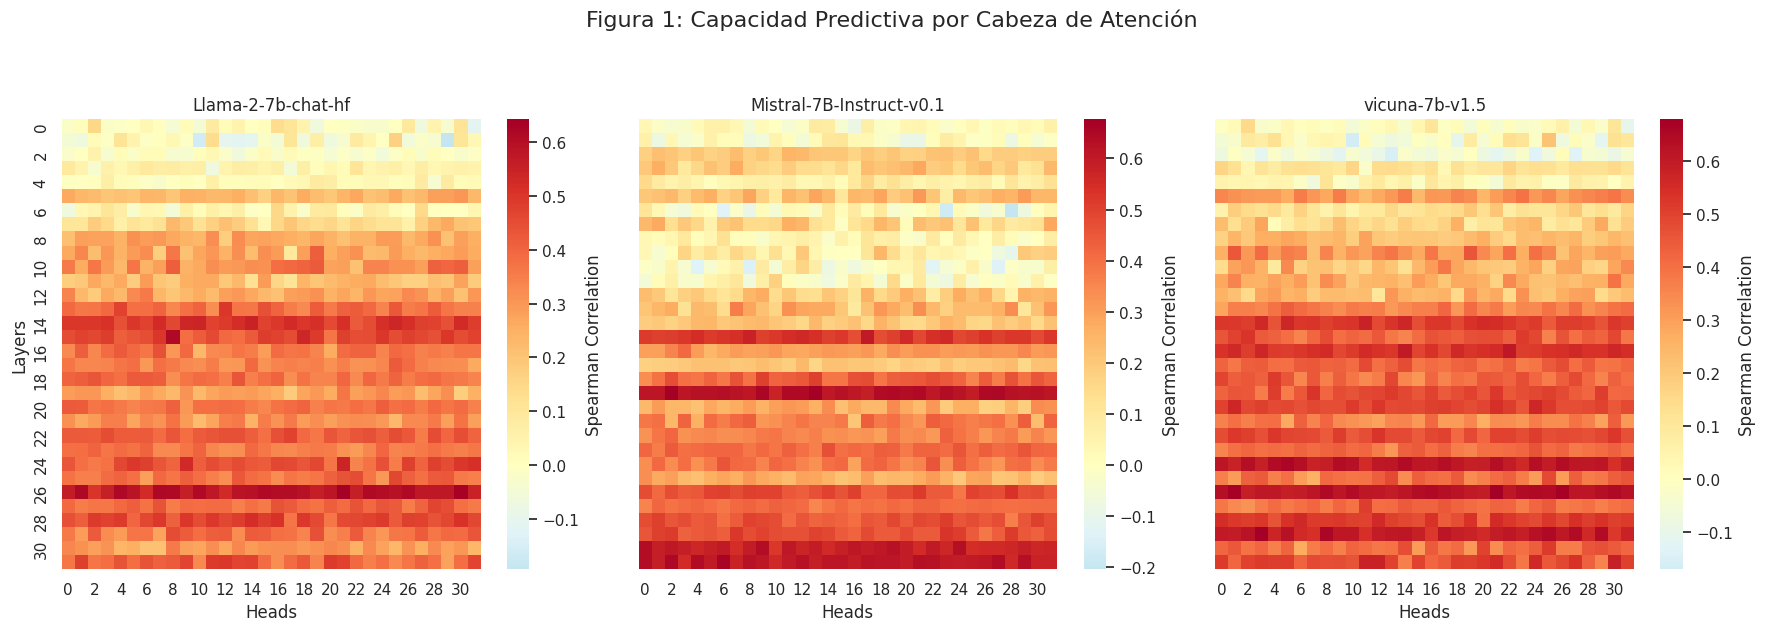

In [3]:
def plot_model_heatmaps(models):
    fig, axes = plt.subplots(1, len(models), figsize=(18, 6), sharey=True)
    
    for i, model_name in enumerate(models):
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        
        if not perf_path.exists():
            print(f"Faltan datos para {model_name}")
            continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
            
        sns.heatmap(performance, ax=axes[i], cmap='RdYlBu_r', center=0, cbar_kws={'label': 'Spearman Correlation'})
        axes[i].set_title(model_name.split('/')[-1])
        axes[i].set_xlabel('Heads')
        if i == 0:
            axes[i].set_ylabel('Layers')
            
    plt.suptitle("Figura 1: Capacidad Predictiva por Cabeza de Atención", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()

plot_model_heatmaps(MODELS)

## 3. Rendimiento por Capa
Visualización del rendimiento máximo y promedio por capa para identificar dónde se concentra la información política.

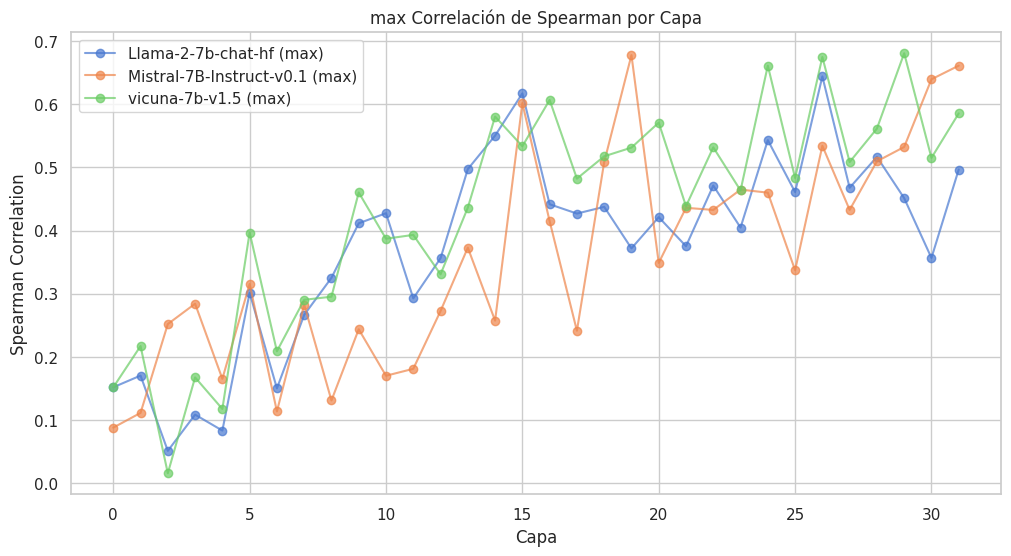

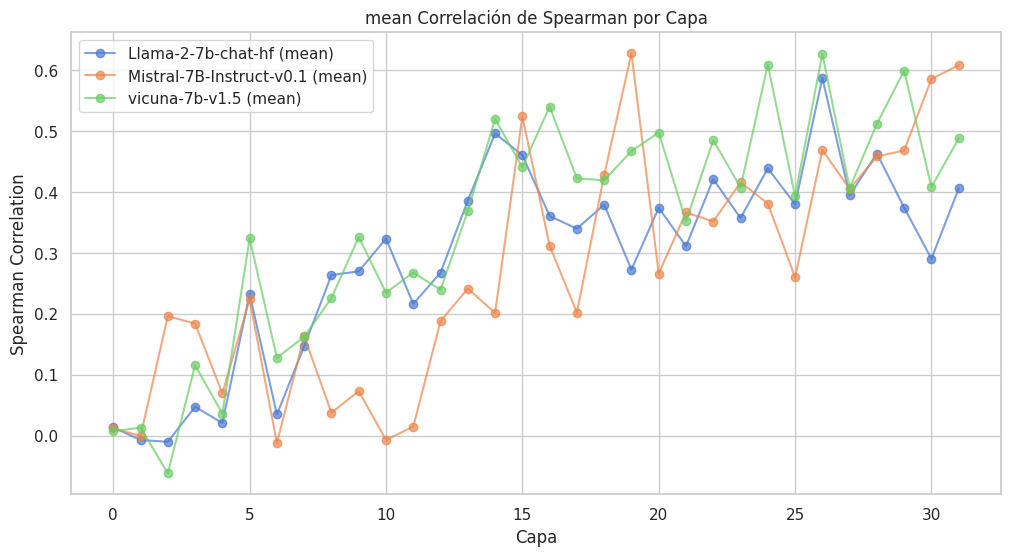

In [14]:
def plot_layer_performance(models, fn):
    plt.figure(figsize=(12, 6))
    
    for model_name in models:
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        
        if not perf_path.exists(): continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
            
        max_perf = fn(performance, axis=1)
        plt.plot(max_perf, label=f"{model_name.split('/')[-1]} ({fn.__name__})", marker='o', alpha=0.7)
        
    plt.title(f"{fn.__name__} Correlación de Spearman por Capa")
    plt.xlabel("Capa")
    plt.ylabel("Spearman Correlation")
    plt.legend()
    plt.show()

plot_layer_performance(MODELS, np.max)
plot_layer_performance(MODELS, np.mean)

## 4. Predictividad de las K-Mejores Probes
Ranking de todas las cabezas por su correlación de Spearman y para observar el rendimiento de las $K$ mejores cabezas de forma agregada.

Máxima correlación para el modelo Llama-2-7b-chat-hf: 0.644
Máxima correlación para el modelo Mistral-7B-Instruct-v0.1: 0.678
Máxima correlación para el modelo vicuna-7b-v1.5: 0.681


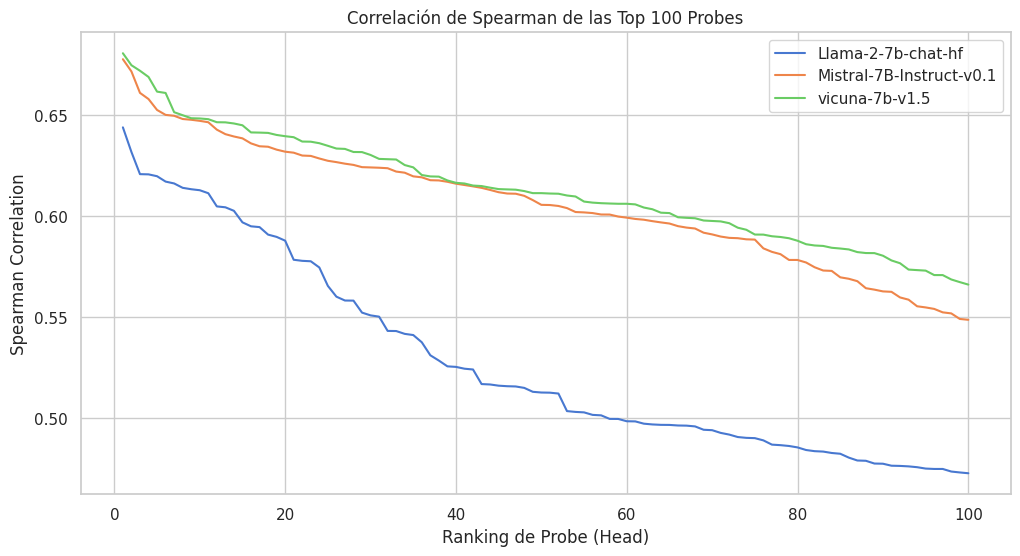

In [21]:
def plot_top_k_performance(models, k_limit=100):
    plt.figure(figsize=(12, 6))
    
    for model_name in models:
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        
        if not perf_path.exists(): continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
            
        # Aplanar y ordenar correlaciones
        sorted_correlations = np.sort(performance.ravel())[::-1]
        k_range = np.arange(1, min(len(sorted_correlations), k_limit) + 1)
        
        plt.plot(k_range, sorted_correlations[:len(k_range)], label=model_name.split('/')[-1])
        print(f"Máxima correlación para el modelo {model_name.split('/')[-1]}: {sorted_correlations[0]:.3f}")
        
    plt.title(f"Correlación de Spearman de las Top {k_limit} Probes")
    plt.xlabel("Ranking de Probe (Head)")
    plt.ylabel("Spearman Correlation")
    plt.legend()
    plt.show()

plot_top_k_performance(MODELS, k_limit=100)

## 5. Scatterplots: NOMINATE Real vs Predicho
Visualización de qué tan cerca están las predicciones del probe más predictivo respecto al puntaje DW_NOMINATE real de cada parlamentario.

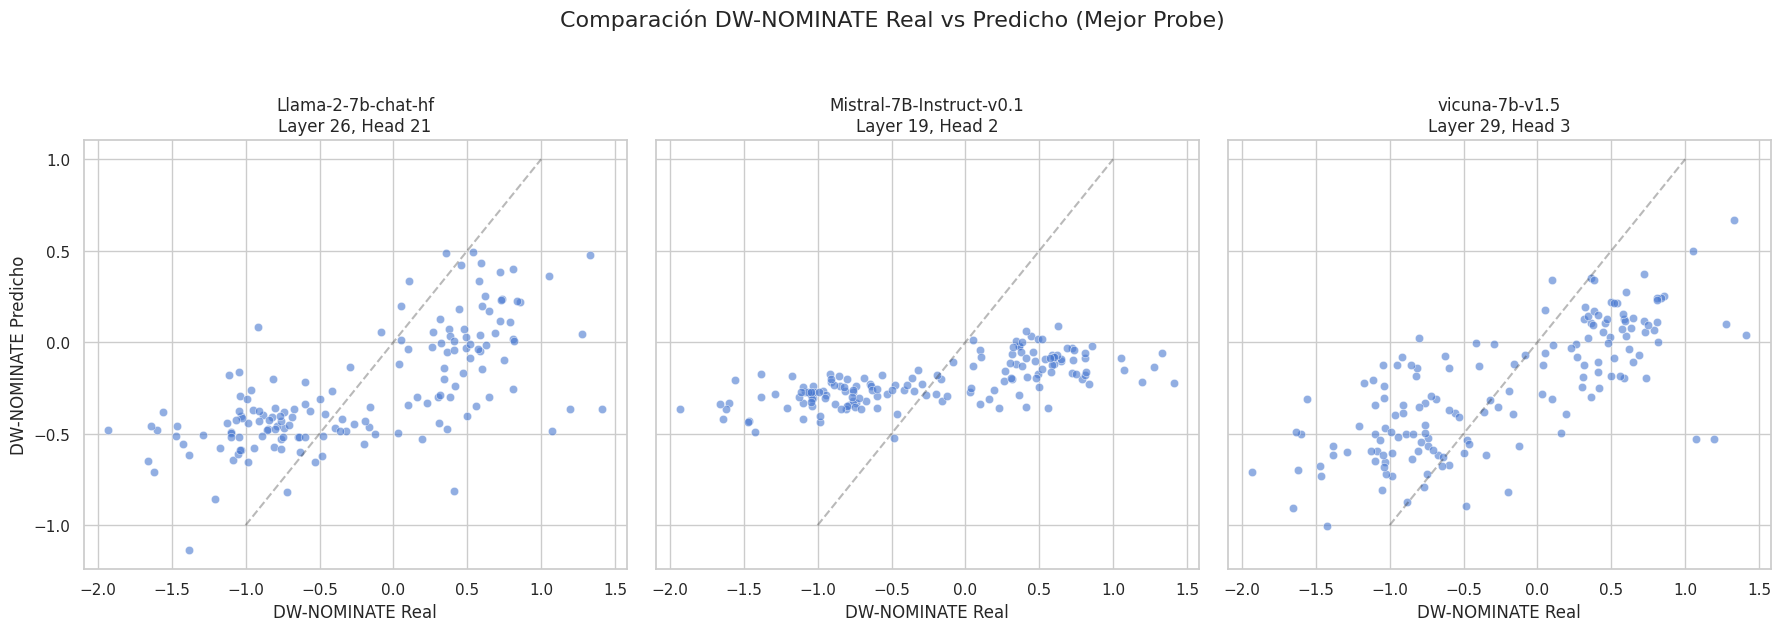

In [15]:
def plot_scatter_real_vs_pred(models):
    fig, axes = plt.subplots(1, len(models), figsize=(18, 6), sharex=True, sharey=True)
    
    for i, model_name in enumerate(models):
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        feat_path = RESULTS_DIR / f"{safe_name}_politician_features.pkl"
        ridge_path = RESULTS_DIR / f"{safe_name}_ridge.pkl"
        
        if not (perf_path.exists() and feat_path.exists() and ridge_path.exists()):
            print(f"Faltan datos para {model_name}")
            continue
            
        performance = pickle.load(open(perf_path, 'rb'))
        features, labels = pickle.load(open(feat_path, 'rb'))
        ridge_dict = pickle.load(open(ridge_path, 'rb'))
        
        # Encontrar la mejor cabeza
        best_layer, best_head = np.unravel_index(np.argmax(performance), performance.shape)
        
        # Predecir con el mejor probe
        best_ridge = ridge_dict[best_layer][best_head]
        X = features[:, best_layer, best_head, :]
        y_pred = best_ridge.predict(X)
        
        # Plot
        sns.scatterplot(x=labels, y=y_pred, ax=axes[i], alpha=0.6)
        # Línea de identidad ideal
        lims = [max(min(labels), min(y_pred)), min(max(labels), max(y_pred))]
        axes[i].plot([-1, 1], [-1, 1], '--k', alpha=0.3)
        
        axes[i].set_title(f"{model_name.split('/')[-1]}\nLayer {best_layer}, Head {best_head}")
        axes[i].set_xlabel("DW-NOMINATE Real")
        if i == 0:
            axes[i].set_ylabel("DW-NOMINATE Predicho")
            
    plt.suptitle("Comparación DW-NOMINATE Real vs Predicho (Mejor Probe)", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()

plot_scatter_real_vs_pred(MODELS)

## 6. Intervención y Political Slant
Revisión de cómo cambian las respuestas del modelo al intervenir las cabezas más predictivas con diferentes intensidades ($\alpha$).

In [18]:
parquet_path = BASE_DIR / "intervention_raw.parquet"
if parquet_path.exists():
    df_intervention = pd.read_parquet(parquet_path)
    print(f"Cargadas {len(df_intervention)} muestras de intervención.")
    
    # Muestra de textos generados para un tópico
    topic = 'inmigración'
    k_fixed = 96
    subset = df_intervention[(df_intervention['topic'] == topic) & (df_intervention['k'] == k_fixed)]
    
    print(f"\nEjemplos de intervención para el tópico '{topic}' (K={k_fixed}):")
    with pd.option_context('display.max_colwidth', None):
        display(subset[['alpha', 'text']].sort_values('alpha'))
else:
    print("No se encontró el archivo intervention_raw.parquet.")

Cargadas 189 muestras de intervención.

Ejemplos de intervención para el tópico 'inmigración' (K=96):


,alpha,text
181,-30,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que \n\n* Es importante reconocer y valorar la diversidad cultural y PCRRRR"
118,-30,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es un tema complejo y multifaceta que requerería un abordaje INTEGRAL y INAUSPCIACA que tenga en cuenta los intereses de todos los INDIVIDUOS INVOLUCINados, pero sobre todo, los INRRIGACINAS A INACUN A INACUN A INACUN INACUN INACUN INACUN INACUN INACUN INACUN"
55,-30,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es importante reconocer que la inmigración es un derecho humano y un derecho fundamental de la humanidad. La inmigración es un proceso natural y necesario en la historia de la humanidad, ya que la humanidad siempre ha migrado en busca de mejoras en la vida, de la lucha contra la opresión, de la lucha por la justicia y de la lumpización de la igualdad."
46,-20,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es importante reconocer que la inmigración es un derecho fundamental de las personas y una necesidad para la sociedad en la actualidad. La inmigración puede ayudar a mejorar la economía, la cultura y la diversidad de la sociedad. Sin embargo, también es importante establecer políticas de inmigración justas y equitativas que protegen los derechos de los migrantes y garantizan la seguridad"
109,-20,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es un tema complejo que requiere una atención abierta y un enfoque humanitario. Los inmigrantes son personas que han elegido dejar su hogar y su cultura para emigrar a otro país y construir una nueva vida allí. Se han mostrado resilientes, perseverantes y capaces de adaptarse en los faced challenges de la migración. Aunque la inmigración puede presentar"
172,-20,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que \n\n* Es importante reconocer y valorar la diversidad cultural y lingüística que trae consigo a nuestro país.\n* La inmigración puede ser una fuente de fortalecimiento para nuestra economía, ya que los inmigrantes pueden traer habilidades y conocimientos que pueden ser útiles en el mercado laboral.\n* Sin embargo, también es importante considerar los impactos que la inmigración"
163,-10,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que \n\n* Es un derecho humano fundamental tener la libertad de elegir el lugar donde vivir y trabajar.\n* La inmigración puede traer beneficios económicas y culturales a un país, pero también puede generar desafíos y tensiones en la sociedad.\n* Es importante establecer políticas de inmigración justas y equitativas que permitan a las personas migrar de manera legal y seg"
37,-10,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es importante reconocer que la inmigración es un derecho humano y un acto de solidaridad. Las personas tienen el derecho de buscar una vida mejor en otros países, y la inmigración puede ayudar a mejorar la diversidad cultural y social de una nación. Sin embargo, también es importante establecer políticas inmigratorias justas y equitativas para garantizar que la inmigración se realice"
100,-10,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que ¡Los individuos tienen el derecho a buscar una mejor vida para sí y sus familias, no importa de dónde vengan o en qué condiciones se encontraban! Toda persona es valiosa y tiene mucho a contribuir, por lo cual merecen ser acogidas, respetadas y brindadas con oportunidades por los países que elegiden para hacer su hogar. La inmigración es una"
154,0,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que \n\n* Es un derecho humano fundamental

## 7. Análisis de Slant
Análisis cualitativo del cambio en el lenguaje según $\alpha$.

In [21]:
if parquet_path.exists():
    # Agrupar por alpha y ver palabras clave frecuentes (simple proxy de slant)
    from collections import Counter
    import re
    
    common_words = {}
    for alpha in sorted(df_intervention['alpha'].unique()):
        texts = " ".join(df_intervention[df_intervention['alpha'] == alpha]['text']).lower()
        words = re.findall(r'\w+', texts)
        # Filtrar stop words comunes (simplificado)
        stop = ['un', 'una', 'el', 'la', 'de', 'que', 'en', 'y', 'a', 'es', 'con', 'por', 'sobre', 'creo', 'respecto', 'declaración', 'user', 'assistant', 'escribe']
        filtered = [w for w in words if w not in stop and len(w) > 3]
        common_words[alpha] = Counter(filtered).most_common(5)
        
    print("Top 5 palabras claves por Alpha (Intensidad de Intervención):")
    for alpha, words in common_words.items():
        print(f"Alpha {alpha}: {', '.join([w[0] for w in words])}")

Top 5 palabras claves por Alpha (Intensidad de Intervención):
Alpha -30: derecho, fundamental, importante, libertad, todos
Alpha -20: para, derecho, importante, armas, libertad
Alpha -10: para, derecho, importante, armas, ciencia
Alpha 0: para, derecho, importante, armas, ciencia
Alpha 10: derecho, todos, para, derechos, libertad
Alpha 20: derecho, importante, derechos, libertad, ciencia
Alpha 30: inherent, inher, importante, confianza, derechos
